# Flow Matching Training

Welcome to the flow matching demo! In this notebook, we will show the process of training a 
flow matching model. 

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from abc import ABC, abstractmethod

from collections.abc import Sequence

import numpy as np
import xarray as xr
import torch
from torch import Tensor

from src.config import load_config
from src.config.schema import SchedulerConfig

In [2]:
CONFIG_PATH = str(Path.cwd().parent) + "/src/config/config.yaml"
DATA_PATH = "/gws/ssde/j25b/ai4climate/user/jar212/sg-workshop-2026-flow/data/jakarta128_8km_to_2km_imperfect"

PREDICTORS_PATH = DATA_PATH + "/predictors"
TARGETS_PATH = DATA_PATH + "/targets"
STATIC_PATH = DATA_PATH + "/static/static_128jakarta_sqrt_normalised.nc"
OUTPUT_PATH = ...

In [4]:
NUM_WORKERS = 8
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

print(f"Using device: {DEVICE}")

config = load_config(CONFIG_PATH)

Using device: cpu


## Load data

First, we will load the predictor and the target dataset. 

We use data from Singapore's Third National Climate Change Study (V3). V3 provides high-resolution climate projections over Southeast Asia by applying a two-stage dynamical downscaling approach; a collection of six CMIP6 GCMs (75-250 km resolution) are downscaled to 8 km over a large region encompassing most of Southeast Asia, and subsequently to 2 km over a smaller inner domain covering Singapore, the Malay Peninsula and Sumatra. The SINGV-RCM regional climate model was used for both downscaling stages. 

In this notebook, we train a model to predict 2 km precipitation from 8 km atmospheric fields, over a cutout centred on [Jakarta/Singapore]. 

In [5]:
# def _parse_years(year_list: list[str | int]) -> list[int]:
#     """Parses a list of years/ranges into a list of integers."""
#     parsed_years: list[int] = []
#     for item in year_list:
#         if isinstance(item, str) and "-" in item:
#             start, end = map(int, item.split("-"))
#             parsed_years.extend(range(start, end + 1))
#         else:
#             parsed_years.append(int(item))
#     return sorted(list(set(parsed_years)))


# def load_dataset(path: str, variables: list[str], years: list[int]) -> xr.Dataset:
#     """Lazily loads dataset for the given variables and years."""
#     ds_list: list[xr.DataArray] = []
#     for var_name in variables:
#         var_path = f"{path}/{var_name}.zarr"
#         ds = xr.open_zarr(var_path, consolidated=True, chunks="auto")
#         ds_list.append(ds[var_name])

#     ds = xr.merge(ds_list)
#     ds = ds.sel(time=ds.time.dt.year.isin(years))
#     return ds

from src.dates import select_date_ranges

def load_dataset(path: str, variables: list[str], date_ranges: Sequence[tuple[str, str]]) -> xr.Dataset:
    """Lazily loads dataset for the given variables and years."""
    ds_list: list[xr.DataArray] = []
    for var_name in variables:
        var_path = f"{path}/{var_name}.zarr"
        ds = xr.open_zarr(var_path, consolidated=True, chunks="auto")
        ds_list.append(ds[var_name])

    ds = xr.merge(ds_list)
    ds = select_date_ranges(ds, date_ranges)
    return ds

In [6]:
# train_years = _parse_years(config.training.years)
# val_years = _parse_years(config.validation.years)

# predictors_ds = load_dataset(PREDICTORS_PATH, list(config.predictors.keys()), train_years)
# targets_ds = load_dataset(TARGETS_PATH, list(config.targets.keys()), train_years)


train_dates = config.training.date_ranges
val_dates = config.validation.date_ranges

predictors_ds = load_dataset(PREDICTORS_PATH, list(config.predictors.keys()), train_dates)
targets_ds = load_dataset(TARGETS_PATH, list(config.targets.keys()), train_dates)

The predictor variables used are temperature, specific humidity and the eastward and northward components of wind, each at 200, 500, 700 and 850 hPa, together with sea-level pressure, taken at daily frequency from the 8 km simulation. We additionally include orography and a land-sea mask at their native 2 km resolution.

In [7]:
predictors_ds

<xarray.Dataset> Size: 1GB
Dimensions:  (lat: 34, lon: 34, time: 14610)
Coordinates:
  * lat      (lat) float64 272B -7.304 -7.232 -7.16 ... -5.072 -5.0 -4.928
  * lon      (lon) float64 272B 105.6 105.7 105.7 105.8 ... 107.8 107.9 108.0
  * time     (time) datetime64[ns] 117kB 1995-01-01 1995-01-02 ... 2099-12-31
Data variables: (12/17)
    hus200   (time, lat, lon) float32 68MB dask.array<chunksize=(14610, 34, 34), meta=np.ndarray>
    hus500   (time, lat, lon) float32 68MB dask.array<chunksize=(14610, 34, 34), meta=np.ndarray>
    hus700   (time, lat, lon) float32 68MB dask.array<chunksize=(14610, 34, 34), meta=np.ndarray>
    hus850   (time, lat, lon) float32 68MB dask.array<chunksize=(14610, 34, 34), meta=np.ndarray>
    ta200    (time, lat, lon) float32 68MB dask.array<chunksize=(14610, 34, 34), meta=np.ndarray>
    ta500    (time, lat, lon) float32 68MB dask.array<chunksize=(14610, 34, 34), meta=np.ndarray>
    ...       ...
    ua850    (time, lat, lon) float32 68MB dask.array<chunksize=(14610, 34, 34), meta=np.ndarray>
    va200    (time, lat, lon) float32 68MB dask.array<chunksize=(14610, 34, 34), meta=np.ndarray>
    va500    (time, lat, lon) float32 68MB dask.array<chunksize=(14610, 34, 34), meta=np.ndarray>
    va700    (time, lat, lon) float32 68MB dask.array<chunksize=(14610, 34, 34), meta=np.ndarray>
    va850    (time, lat, lon) float32 68MB dask.array<chunksize=(14610, 34, 34), meta=np.ndarray>
    psl      (time, lat, lon) float32 68MB dask.array<chunksize=(14610, 34, 34), meta=np.ndarray>
Attributes:
    long_name:        SPECIFIC HUMIDITY ON P LEV/T GRID
    cell_methods:     T6HR: point
    um_version:       11.1
    um_stash_source:  m01s30i295
    packing_method:   none

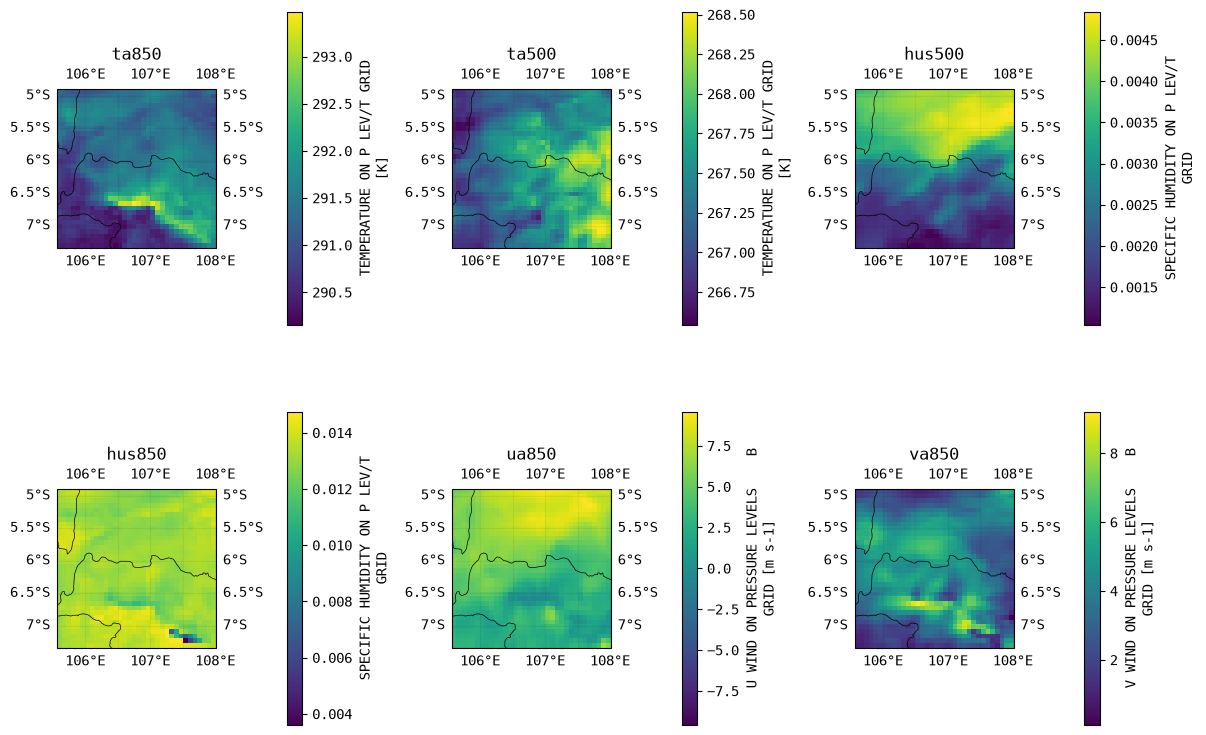

In [11]:
from src.plotting import plot_predictors


plot_predictors(
    ds=predictors_ds,
    variables=["ta850", "ta500", "hus500", "hus850", "ua850", "va850"],
    time_idx=0,
)

The target variable is daily precipitation, at 2 km resolution. 

In [19]:
targets_ds

<xarray.Dataset> Size: 958MB
Dimensions:  (lat: 128, lon: 128, time: 14610)
Coordinates:
  * lat      (lat) float64 1kB -7.29 -7.272 -7.254 ... -5.04 -5.022 -5.004
  * lon      (lon) float64 1kB 105.7 105.7 105.7 105.7 ... 107.9 107.9 107.9
  * time     (time) datetime64[ns] 117kB 1995-01-01 1995-01-02 ... 2099-12-31
Data variables:
    pr       (time, lat, lon) float32 957MB dask.array<chunksize=(1992, 128, 128), meta=np.ndarray>
Attributes:
    standard_name:    stratiform_rainfall_flux
    long_name:        LARGE SCALE RAINFALL RATE    KG/M2/S
    units:            kg m-2 s-1
    cell_methods:     HIRES_MN: point
    um_version:       11.1
    um_stash_source:  m01s04i203
    packing_method:   none

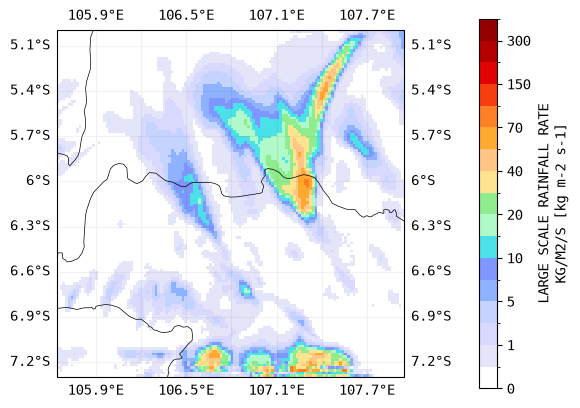

In [18]:
from src.plotting import plot_field


plot_field(
    ds=targets_ds,
    time_idx=0,
    variable="pr",
    units="mm day-1",
)

The data is split temporally into training, validation and test sets. The training set comprises 1995-2014 and 2080-2099, exposing the model to two distinct climates spanning recent-past and end-of-century conditions. The validation set is 2040-2049, and the test set is 2050-2059.

In [13]:
years_present = np.unique(predictors_ds.time.dt.year.values)
print("Training years present:", years_present)
print("\nTotal training timesteps:", predictors_ds.sizes["time"])

Training years present: [1995 1996 1997 1998 1999 2000 2001 2002 2003 2004 2005 2006 2007 2008
 2009 2010 2011 2012 2013 2014 2080 2081 2082 2083 2084 2085 2086 2087
 2088 2089 2090 2091 2092 2093 2094 2095 2096 2097 2098 2099]

Total training timesteps: 14610


## Fit transforms

In [ ]:
from src.transforms import Transform, fit_transforms, save_transforms

The atmospheric predictor variables are normalised with z-score normalisation, so that they have zero mean and unit variance. This helps training, as it ensures the predictor variables are on the same scale -- allowing the network to understand patterns in the data. 

The normalisation statistics (mean and standard deviation for each variable) are calculated over the training set. Normalisation will be applied to each of the training, validation and test sets. 

As the target precipitation has a very skewed, gamma distribution, we instead use a square-root transform and then min-max scale to the range -1 to 1.


In [ ]:
predictor_transforms = fit_transforms(config, predictors_ds, groups=["predictors"])
target_transforms = fit_transforms(config, targets_ds, groups=["targets"])

transforms: dict[str, dict[str, Transform]] = {
    "predictors": predictor_transforms["predictors"],
    "targets": target_transforms["targets"],
}

save_transforms(transforms, f"{OUTPUT_PATH}/transforms.json")

## Initialise Datasets and Dataloaders

In [ ]:
from src.dataset import V3Dataset

When using PyTorch (a popular Python framework for building and training machine learning models), data is loaded using `DataLoader`s. `DataLoader`s allow us to efficiently sample batches of data (predictors and associated target field) from our dataset. The (normalisation) transforms are applied whilst loading the data - see `dataset.py` for details of how we process the data samples before providing them to the model.  

In [ ]:
training_dataset = V3Dataset(
    predictors_path=PREDICTORS_PATH,
    targets_path=TARGETS_PATH,
    config=config,
    date_ranges=train_dates,
    transforms=transforms,
    static_path=STATIC_PATH,
)
validation_dataset = V3Dataset(
    predictors_path=PREDICTORS_PATH,
    targets_path=TARGETS_PATH,
    config=config,
    date_ranges=val_dates,
    transforms=transforms,
    static_path=STATIC_PATH,
)

batch_size = config.training.batch_size
training_dataloader = torch.utils.data.DataLoader(
    training_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
)
validation_dataloader = torch.utils.data.DataLoader(
    validation_dataset,
    batch_size=batch_size,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True,
)

## Intro to flow matching

Flow matching is a generative modelling framework, which can be used to generate stochastic samples of precipitation, conditioned on atmospheric driving fields. Flow matching generates predictions by:
* sampling from a source/initial distribution (typically Gaussian noise)
* mapping/transporting the initial sample to the target data distribution (for us, that is precipitation conditioned on the atmospheric fields), by simulating an ODE. 

During training, we:
* sample a (predictors, target) pair, as well as a sample $x_0$ from the source distribution
* calculate an interpolant $x_t$ between the sample from the source distribution and the target: $x_t = \alpha_t x_1 + \beta_t x_0$ ($x_1$ denotes the target, $x_0$ the sample from the source distribution)
* ask the neural network to predict the 'velocity field'; that is, the direction to move at time $t$ to flow from noise toward data.

The neural network is optimised using standard machine learning techniques - backpropagation and gradient descent - such that it is able to map samples from the initial distribution to the target data distribution (by simulating the ODE defined by the learnt velocity field). 

Note that during training we never actually integrate the ODE. 

## Source/Initial distribution 

We use a standard Gaussian distribution as our source distribution. 

In [ ]:
class GaussianDistribution:
    """Gaussian distribution sampler."""

    def __init__(self, mean: float, std: float, device: torch.device):
        """Initialise Gaussian distribution sampler.

        Args:
            mean: Mean of the Gaussian distribution.
            std: Standard deviation of the Gaussian distribution.
            device: Device to place samples on.
        """
        self.mean = mean
        self.std = std
        self.device = device

    def sample(self, shape: tuple) -> torch.Tensor:
        return torch.normal(self.mean, self.std, size=shape, device=self.device)

In [ ]:
source_sampler = GaussianDistribution(
    mean=config.source.mean, std=config.source.std, device=DEVICE
)

## Configure probability path / interpolant

Recall the interpolant is: $$x_t = \alpha_t x_1 + \beta_t x_0$$

Here, $\alpha_t$ and $\beta_t$ are called the 'noise schedulers'. For a given $t \in [0, 1]$, they determine how close to noise or data the interpolant is. Any $\alpha_t$, $\beta_t$ satisfying $\alpha_0 = \beta_1 = 0$ and $\alpha_1 = \beta_0 = 1$ can be used, such that $t=0$ corresponds to pure noise and $t=1$ corresponds to data. 

A common choice is $\alpha_t = t$ and $\beta_t = 1-t$ (this is the `CondOTScheduler` class below).

In [ ]:
# Noise schedulers for affine probability paths - alpha_t and beta_t

class Scheduler(ABC):
    def __init__(self, **kwargs): ...

    @abstractmethod
    def __call__(self, t: Tensor) -> tuple[Tensor, Tensor]:
        """Return alpha_t and beta_t

        Args:
            t: Times in [0, 1], shape (...)

        Returns:
            alpha_t: alpha_t, shape (...)
            beta_t: beta_t, shape (...)
        """
        pass

    @abstractmethod
    def derivative(self, t: Tensor) -> tuple[Tensor, Tensor]:
        """Returns the time-derivative of alpha_t and beta_t

        Args:
            t: Time in [0, 1], shape (...)

        Returns:
            d_alpha_t: Time derivative of alpha_t, shape (...)
            d_beta_t: Time derivative of beta_t, shape (...)
        """
        pass


class CondOTScheduler(Scheduler):
    """CondOT (linear) scheduler.

    alpha_t = t, beta_t = 1 - t
    """

    def __call__(self, t: Tensor) -> tuple[Tensor, Tensor]:
        return t, 1.0 - t

    def derivative(self, t: Tensor) -> tuple[Tensor, Tensor]:
        return torch.ones_like(t), -1 * torch.ones_like(t)


# Included to demonstrate alternative schedulers.
class PolynomialScheduler(Scheduler):
    """Polynomial scheduler."""

    def __init__(self, n: float | int, **kwargs):
        if n <= 0:
            raise ValueError(f"n must be positive. Got n={n}")
        self.n = n

    def __call__(self, t: Tensor) -> tuple[Tensor, Tensor]:
        return t**self.n, 1 - t**self.n

    def derivative(self, t: Tensor) -> tuple[Tensor, Tensor]:
        d_alpha_t = self.n * (t ** (self.n - 1))
        d_beta_t = -1 * self.n * (t ** (self.n - 1))
        return d_alpha_t, d_beta_t


SCHEDULER_REGISTRY = {
    "condot": CondOTScheduler,
    "polynomial": PolynomialScheduler,
}
"""Mapping from scheduler name to class."""

In [ ]:
# Probability paths

class AffineProbabilityPath:
    def __init__(self, scheduler: Scheduler):
        self.scheduler = scheduler

    def sample(self, x_0: Tensor, x_1: Tensor, t: Tensor) -> Tensor:
        """Returns samples from the path.

        X_t = alpha_t * X_1 + beta_t * X_0

        Args:
            x_0: Source points, shape (batch_size, ...)
            x_1: Target points, shape (batch_size, ...)
            t: Times between [0, 1], shape (batch_size, 1).

        Returns:
            x_t: Samples from path, shape (batch_size, ...)
        """
        t = self._expand_t(t, x_0)
        alpha_t, beta_t = self.scheduler(t)
        x_t = alpha_t * x_1 + beta_t * x_0
        return x_t

    def compute_vector_field(self, x_0: Tensor, x_1: Tensor, t: Tensor) -> Tensor:
        """Returns the conditional vector/velocity field at time t and position x_t.

        dX_t/dt = (d_alpha_t - d_beta_t/beta_t * alpha_t) * X_1 + d_beta_t/beta_t * X_t

        Equivalently, in terms of X_0 and X_1: dX_t/dt = d_alpha_t * X_1 + d_beta_t * X_0

        Args:
            x_0: Source points, shape (batch_size, ...)
            x_1: Target points, shape (batch_size, ...)
            t: Times between [0, 1], shape (batch_size, 1).

        Returns:
            v_t: Velocity values at time t and position x_t, shape (batch_size, ...)
        """
        t = self._expand_t(t, x_0)
        d_alpha_t, d_beta_t = self.scheduler.derivative(t)
        v_t = d_alpha_t * x_1 + d_beta_t * x_0
        return v_t

    def _expand_t(self, t: Tensor, x: Tensor) -> Tensor:
        if t.ndim != 2 or t.shape[1] != 1:
            raise ValueError(f"t must have shape (B, 1), got {t.shape}")
        # Expand to (batch_size, 1, ..., 1)
        return t.view(t.shape[0], *([1] * (x.ndim - 1)))


class CondOTPath(AffineProbabilityPath):
    """Special case of the affine probability path, where alpha=t and beta=1-t.

    The expression for the conditional vector field simplifies in this case.
    """

    def compute_vector_field(self, x_0: Tensor, x_1: Tensor, t: Tensor) -> Tensor:
        """Returns the conditional vector field at time t and position x_t.

        dX_t/dt = d_alpha_t * X_1 + d_beta_t * X_0 = X_1 - X_0

        Equivalently, in terms of X_0 and X_1: dX_t/dt = X_1 - X_0
        """
        return x_1 - x_0


In [ ]:
scheduler_config: SchedulerConfig = config.scheduler
scheduler_type = scheduler_config.type
scheduler = SCHEDULER_REGISTRY[scheduler_type](**scheduler_config.model_dump())

probability_path = CondOTPath(scheduler) if scheduler_type == "condot" else AffineProbabilityPath(scheduler)

## Initialise model

We use a U-Net to predict the velocity field. The U-Net takes as input the noisy interpolant $x_t$, the (non-physical) time $t$, and the predictor variables (these are commonly referred to as 'conditioning' variables, as the prediction is conditioned on these fields), and predicts the velocity field. 

The particular U-Net architecture we use (ADM) is from OpenAI's 'Diffusion Models Beat GANs on Image Synthesis' (Dhariwal & Nichol, 2021) paper. Other architectures - such as graph networks - can also be used to predict the velocity field. 

In [ ]:
from src.network import ADM


static_variables = config.static or []
if static_variables:
    print(f"Using static variables: {static_variables}")
else:
    print("Not using static variables")
if config.pos_emb:
    print("Using sinusoidal positional embeddings (4 channels)")
num_conditioning_variables = (
    len(config.predictors) + len(static_variables) + (4 if config.pos_emb else 0)
)

model = ADM(
    num_conditioning_variables=num_conditioning_variables,
    num_target_variables=len(config.targets),
    **config.model.model_dump(),
).to(DEVICE)

In [ ]:
print(f"Number of parameters: {sum(p.numel() for p in model.parameters())}")

## Run training loop

We can now train the U-Net to predict the velocity field. Despite the generative end goal, each training step is an ordinary supervised regression. For every batch we draw a noise sample $x_0$ from the source distribution and a time $t \sim \mathrm{Unif}(0, 1)$, form the interpolant $x_t = \alpha_t x_1 + \beta_t x_0$, and compute the *target* velocity $v_t$ analytically from the probability path (for the linear/CondOT path, simply $x_1 - x_0$). The network predicts a velocity $u_\theta(x_t, t, c)$ from the interpolant, the time $t$, and the conditioning fields $c$, and we minimise the mean-squared error between prediction and target:

$$\mathcal{L} = \mathbb{E}_{t,\, x_0,\, (x_1, c)} \left\| u_\theta(x_t, t, c) - v_t \right\|^2.$$

The weights are updated by gradient descent (here the AdamW optimiser). As noted earlier, the ODE is never integrated during training -- we only regress on the known per-sample velocity.

In [ ]:
# Configuration

learning_rate = config.training.learning_rate
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
loss_fn = torch.nn.MSELoss()
epochs = config.training.epochs

This is repeated over many passes through the training set (*epochs*). After each epoch we evaluate on the held-out validation years and keep the weights with the lowest validation loss; if that loss fails to improve for `patience` epochs, we stop early. We also maintain an exponential moving average (EMA) of the weights -- a smoothed version of the model that typically produces better samples -- and it is this EMA model that we validate and checkpoint.

In [ ]:
# Exponential moving average setup

from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn


ema_decay = config.training.ema_decay
if ema_decay is not None:
    print(f"Using EMA with decay={ema_decay}")
    ema_model = AveragedModel(
        model, multi_avg_fn=get_ema_multi_avg_fn(ema_decay), use_buffers=True
    )
else:
    ema_model = None

# Model used for validation and checkpointing: the EMA weights when EMA is enabled,
# otherwise the online weights.
eval_model = ema_model if ema_model is not None else model

In [ ]:
from copy import deepcopy

from src.train import train_loop, val_loop


best_val_loss = torch.inf
best_model_state = None
patience = config.training.patience
epochs_without_improvement = 0

gradient_accumulation_steps = config.training.gradient_accumulation_steps

for epoch in range(epochs):
    print(f"Epoch {epoch+1}\n-------------------------------")
    train_loop(
        dataloader=training_dataloader,
        model=model,
        loss_fn=loss_fn,
        optimizer=optimizer,
        device=DEVICE,
        epoch=epoch,
        coupled=False,
        source_sampler=source_sampler,
        probability_path=probability_path,
        gradient_accumulation_steps=gradient_accumulation_steps,
        conditioning_dropout=config.training.conditioning_dropout,
        use_amp=True,
        ema_model=ema_model,
    )

    val_loss = val_loop(
        dataloader=validation_dataloader,
        model=eval_model,
        loss_fn=loss_fn,
        device=DEVICE,
        epoch=epoch,
        coupled=False,
        source_sampler=source_sampler,
        probability_path=probability_path,
        use_amp=True,
    )
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        checkpoint_module = eval_model.module if ema_model is not None else model
        best_model_state = deepcopy(checkpoint_module.state_dict())
        epochs_without_improvement = 0
    else:
        if patience is not None:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f"No improvement in validation loss for {patience} epochs. Early stopping.")
                break

model_path = f"{OUTPUT_PATH}/model.pth"
print(f"Training complete. Saving model to {model_path}")
torch.save(best_model_state, model_path)